# ЛР 12. Электронная энергия H2: исполняемый RHF/STO-3G

**Сущность:** Проследить электронный расчёт от интегралов до сходимости и различить E, G и барьер.

**Данные:** Два атома H, расстояние 0,74 Å; стандартные параметры STO-3G заданы явно в h2_scf.py.

**Workflow:** S/H/ERI → F[P] → FC=SCε → плотность → сходимость → кривая энергии.

Перед запуском прочитайте [guideline](../guides/lab12.md) и [теорию](../../Module_theory/Module%2012_quatium%20chemistry.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [1]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab12"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Прочитайте ограничение реализации: только H2, закрытая оболочка, s-функции.
2. Посчитайте энергию и проверьте контрольное значение около −1,1167593 Hartree.
3. Просканируйте расстояние, затем объясните, почему этот расчёт не даёт ΔG и активационный барьер.

Ожидаемое: RHF/STO-3G при 0,74 Å: −1,116759307±5e−5 Hartree. Все точки должны сходиться. Это HF, не выполненный DFT.

{'distance_angstrom': 0.74, 'energy_hartree': -1.1167593073781579, 'converged': True, 'cycles': 2, 'trace': [{'cycle': 1, 'energy_hartree': -1.116759307378158, 'density_change': 5.438959822042073e-16}, {'cycle': 2, 'energy_hartree': -1.1167593073781579, 'density_change': 2.7194799110210365e-16}], 'method': 'RHF/STO-3G; restricted H2 only'}


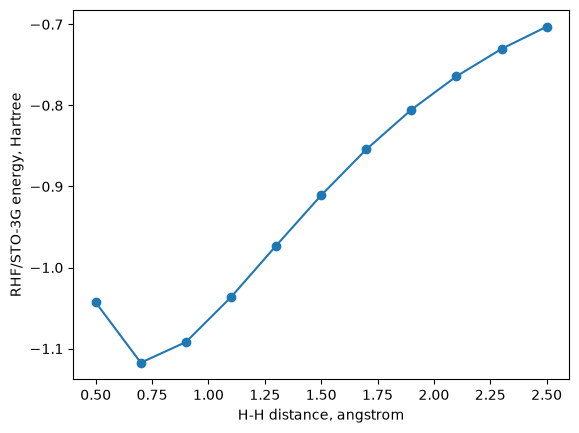

In [2]:
from h2_scf import rhf_h2
result=rhf_h2(0.74)
print(result)
assert result["converged"]
assert abs(result["energy_hartree"]-(-1.116759307))<5e-5
assert math.isclose(-0.010*2625.5,-26.255,abs_tol=1e-9)
scan=pd.DataFrame([{"R_A":r,"E_hartree":rhf_h2(float(r))["energy_hartree"]} for r in np.linspace(0.5,2.5,11)])
scan.to_csv(OUT/"h2_scan.csv",index=False)
plt.plot(scan.R_A,scan.E_hartree,"o-");plt.xlabel("H-H distance, angstrom");plt.ylabel("RHF/STO-3G energy, Hartree")
plt.savefig(OUT/"h2_energy.png",dpi=150);plt.show()
artifact={"single_point":result,"minimum_of_grid":float(scan.E_hartree.min()),"DFT_executed":False}


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [3]:
elapsed = time.perf_counter()-started
run_record = {"lab": 12, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\Labs\results\lab12\benchmark.json


## 4. Самостоятельная тренировка

1. Переведите разность −0,010 Hartree в кДж/моль.
2. Найдите слагаемое отталкивания ядер и объясните ошибку его пропуска.
3. Почему растянутая RHF-кривая не даёт корректную диссоциацию?

[Ответы после попытки](../solutions/lab12.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.